In [1]:
# ============================================================
# CELL 1 — INSTALL REQUIRED LIBRARIES
# ============================================================

!pip -q install xgboost catboost shap openpyxl

print("Libraries installed successfully!")

Libraries installed successfully!



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Python314\python.exe -m pip install --upgrade pip


In [2]:
chemical_file = "C:\\waterprediction\\swq_chemical_parameter_manual_cpcb_ap_2021_2025.csv"
physical_file = "C:\\waterprediction\\swq_physical_parameter_manual_cpcb_ap_2021_2025.csv"
biological_file = "C:\\waterprediction\\swq_biological_parameter_manual_cpcb_ap_2021_2025.csv"

print("File paths set.")

File paths set.


In [3]:
# ============================================================
# CELL 2 — IMPORT LIBRARIES
# ============================================================

import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")



from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# ============================================================
# CELL 3 — LOAD DATASETS
# ============================================================

files_to_load = {
    "chemical": chemical_file,
    "physical": physical_file,
    "biological": biological_file,
}

missing_files = [path for path in files_to_load.values() if not os.path.isfile(path)]
if missing_files:
    raise FileNotFoundError(
        "The following dataset files were not found:\n" + "\n".join(missing_files)
    )

print("Datasets found:")
for dataset_name, file_path in files_to_load.items():
    print(f" - {dataset_name}: {file_path}")

Datasets found:
 - chemical: C:\waterprediction\swq_chemical_parameter_manual_cpcb_ap_2021_2025.csv
 - physical: C:\waterprediction\swq_physical_parameter_manual_cpcb_ap_2021_2025.csv
 - biological: C:\waterprediction\swq_biological_parameter_manual_cpcb_ap_2021_2025.csv


In [5]:
csv_files = [
    chemical_file,
    physical_file,
    biological_file,
]

print("\nCSV files found:")
for file_path in csv_files:
    print(os.path.basename(file_path))


CSV files found:
swq_chemical_parameter_manual_cpcb_ap_2021_2025.csv
swq_physical_parameter_manual_cpcb_ap_2021_2025.csv
swq_biological_parameter_manual_cpcb_ap_2021_2025.csv


In [6]:
# ============================================================
# CELL 4 — IDENTIFY CHEMICAL / PHYSICAL / BIOLOGICAL FILES
# ============================================================

def find_file(keyword):
    matches = [
        f for f in csv_files
        if keyword.lower() in os.path.basename(f).lower()
    ]

    if len(matches) == 0:
        return None

    return matches[0]


chemical_file = find_file("chemical")
physical_file = find_file("physical")
biological_file = find_file("biological")

print("Chemical :", chemical_file)
print("Physical :", physical_file)
print("Biological:", biological_file)

# If automatic detection fails, manually set the names here.
# Example:
#
# chemical_file = "/content/your_chemical_file.csv"
# physical_file = "/content/your_physical_file.csv"
# biological_file = "/content/your_biological_file.csv"

if not all([chemical_file, physical_file, biological_file]):
    raise FileNotFoundError(
        "Could not automatically identify all 3 datasets. "
        "Set chemical_file, physical_file and biological_file manually."
    )

Chemical : C:\waterprediction\swq_chemical_parameter_manual_cpcb_ap_2021_2025.csv
Physical : C:\waterprediction\swq_physical_parameter_manual_cpcb_ap_2021_2025.csv
Biological: C:\waterprediction\swq_biological_parameter_manual_cpcb_ap_2021_2025.csv


In [7]:
# ============================================================
# CELL 5 — LOAD DATA
# ============================================================

chemical = pd.read_csv(chemical_file)
physical = pd.read_csv(physical_file)
biological = pd.read_csv(biological_file)

print("CHEMICAL SHAPE :", chemical.shape)
print("PHYSICAL SHAPE :", physical.shape)
print("BIOLOGICAL SHAPE:", biological.shape)

CHEMICAL SHAPE : (1829, 52)
PHYSICAL SHAPE : (1393, 25)
BIOLOGICAL SHAPE: (1811, 23)


In [8]:
# ============================================================
# CELL 6 — STANDARDIZE COLUMN NAMES
# ============================================================

def clean_columns(df):

    df = df.copy()

    df.columns = (
        df.columns
        .astype(str)
        .str.strip()
        .str.replace("\n", " ", regex=False)
        .str.replace(r"\s+", "_", regex=True)
        .str.replace("(", "", regex=False)
        .str.replace(")", "", regex=False)
        .str.replace("/", "_", regex=False)
        .str.replace("-", "_", regex=False)
        .str.replace(".", "_", regex=False)
        .str.replace("%", "pct", regex=False)
    )

    return df


chemical = clean_columns(chemical)
physical = clean_columns(physical)
biological = clean_columns(biological)

print("Chemical columns:")
print(chemical.columns.tolist())

print("\nPhysical columns:")
print(physical.columns.tolist())

print("\nBiological columns:")
print(biological.columns.tolist())

Chemical columns:
['SlNo', 'Station', 'Agency', 'State_LGD_Code', 'State', 'District_LGD_Code', 'District', 'Tehsil', 'Block', 'Village', 'River', 'Basin', 'Tributary', 'Subtributary', 'SubSubtributary', 'Local_River', 'Latitude', 'Longitude', 'Data_Acquisition_Time', 'Amonia_N_mgN_L', 'Boron_mg_L', 'Carbonate_mg_L', 'Calcium_mg_L', 'Chloride_mg_L', 'Dissolved_oxygen_mg_L', 'Total_Dissolved_Solids_mg_L', 'Fluoride_mg_L', 'Bicarbonate_mg_L', 'Potassium_mg_L', 'Magnesium_mg_L', 'Sodium_mg_L', 'Nitrite_N+Nitrate_N_mgN_L', 'Potential_of_Hydrogen_pH', 'Sulphate_mg_L', 'Total_Phosphorus_mgP_L', 'Arsenic_mg_L', 'Total_Alkalinity_mg_L_as_CaCO3', 'Cadmium_mg_L', 'Chromium_mg_L', 'Ironmg_L', 'Hardness_Calcium_mgCaCO3_L', 'Mercurymg_L', 'Hardness_Magnesium_mg_L_as_CaCO3', 'Total_Hardness_mgCaCO3_L', 'Manganese_mg_L', 'Nitrate_N_mgN_L', 'Nickel_mg_L', 'Lead_mg_L', 'Zinc_mg_L', 'Sodium_Adsorption_Ratio_pct', 'Nitrate_mg_L', 'Copper_mg_L']

Physical columns:
['SlNo', 'Station', 'Agency', 'State_LGD_

In [9]:
# ============================================================
# CELL 7 — CONVERT NUMERIC MEASUREMENTS
# ============================================================

def convert_numeric_columns(df):

    df = df.copy()

    for col in df.columns:

        # Try numeric conversion
        converted = pd.to_numeric(df[col], errors="coerce")

        # If enough values convert successfully, use numeric version
        non_null_original = df[col].notna().sum()

        if non_null_original > 0:
            conversion_rate = converted.notna().sum() / non_null_original

            if conversion_rate >= 0.70:
                df[col] = converted

    return df


chemical = convert_numeric_columns(chemical)
physical = convert_numeric_columns(physical)
biological = convert_numeric_columns(biological)

print("Numeric conversion completed.")

Numeric conversion completed.


In [10]:
# ============================================================
# CELL 8 — FIND COMMON IDENTIFIER COLUMNS
# ============================================================

print("COMMON COLUMNS")
print("=" * 60)

common_columns = (
    set(chemical.columns)
    & set(physical.columns)
    & set(biological.columns)
)

for col in sorted(common_columns):
    print(col)

COMMON COLUMNS
Agency
Basin
Block
Data_Acquisition_Time
District
District_LGD_Code
Latitude
Local_River
Longitude
River
SlNo
State
State_LGD_Code
Station
SubSubtributary
Subtributary
Tehsil
Tributary
Village


In [11]:
# ============================================================
# CELL 9 — CREATE MERGE KEY
# ============================================================

STATION_COL = "Station"
DATE_COL = "Data_Acquisition_Time"

# Check required columns
for name, df in {
    "Chemical": chemical,
    "Physical": physical,
    "Biological": biological
}.items():

    if STATION_COL not in df.columns:
        raise KeyError(
            f"{STATION_COL} not found in {name} dataset.\n"
            f"Available columns:\n{df.columns.tolist()}"
        )

    if DATE_COL not in df.columns:
        raise KeyError(
            f"{DATE_COL} not found in {name} dataset.\n"
            f"Available columns:\n{df.columns.tolist()}"
        )


def create_merge_key(df):

    df = df.copy()

    # Convert acquisition time to datetime
    df[DATE_COL] = pd.to_datetime(
        df[DATE_COL],
        errors="coerce"
    )

    # Create Station + Date merge key
    df["Merge_Key"] = (
        df[STATION_COL]
        .astype(str)
        .str.strip()
        + "_"
        + df[DATE_COL]
        .dt.strftime("%Y-%m-%d")
    )

    return df


# Apply to all three datasets
chemical = create_merge_key(chemical)
physical = create_merge_key(physical)
biological = create_merge_key(biological)

print("✓ Merge keys created successfully!")

print("\nChemical:")
display(
    chemical[
        [STATION_COL, DATE_COL, "Merge_Key"]
    ].head()
)

print("\nPhysical:")
display(
    physical[
        [STATION_COL, DATE_COL, "Merge_Key"]
    ].head()
)

print("\nBiological:")
display(
    biological[
        [STATION_COL, DATE_COL, "Merge_Key"]
    ].head()
)

✓ Merge keys created successfully!

Chemical:


,Station,Data_Acquisition_Time,Merge_Key
0,AMBER CHERUVU KUKATPALLY RANGA REDDY,2021-12-01 08:30:00,AMBER CHERUVU KUKATPALLY RANGA REDDY_2021-12-01
1,AMBER CHERUVU KUKATPALLY RANGA REDDY,NaT,NaN
2,AMBER CHERUVU KUKATPALLY RANGA REDDY,2021-11-06 08:30:00,AMBER CHERUVU KUKATPALLY RANGA REDDY_2021-11-06
3,AMBER CHERUVU KUKATPALLY RANGA REDDY,2021-09-07 08:30:00,AMBER CHERUVU KUKATPALLY RANGA REDDY_2021-09-07
4,AMBER CHERUVU KUKATPALLY RANGA REDDY,2021-02-09 08:30:00,AMBER CHERUVU KUKATPALLY RANGA REDDY_2021-02-09



Physical:


,Station,Data_Acquisition_Time,Merge_Key
0,AMBER CHERUVU KUKATPALLY RANGA REDDY,2021-12-01 08:30:00,AMBER CHERUVU KUKATPALLY RANGA REDDY_2021-12-01
1,AMBER CHERUVU KUKATPALLY RANGA REDDY,NaT,NaN
2,AMBER CHERUVU KUKATPALLY RANGA REDDY,2021-11-06 08:30:00,AMBER CHERUVU KUKATPALLY RANGA REDDY_2021-11-06
3,AMBER CHERUVU KUKATPALLY RANGA REDDY,2021-09-07 08:30:00,AMBER CHERUVU KUKATPALLY RANGA REDDY_2021-09-07
4,AMBER CHERUVU KUKATPALLY RANGA REDDY,2021-02-09 08:30:00,AMBER CHERUVU KUKATPALLY RANGA REDDY_2021-02-09



Biological:


,Station,Data_Acquisition_Time,Merge_Key
0,AMBER CHERUVU KUKATPALLY RANGA REDDY,2021-12-01 08:30:00,AMBER CHERUVU KUKATPALLY RANGA REDDY_2021-12-01
1,AMBER CHERUVU KUKATPALLY RANGA REDDY,NaT,NaN
2,AMBER CHERUVU KUKATPALLY RANGA REDDY,2021-11-06 08:30:00,AMBER CHERUVU KUKATPALLY RANGA REDDY_2021-11-06
3,AMBER CHERUVU KUKATPALLY RANGA REDDY,2021-09-07 08:30:00,AMBER CHERUVU KUKATPALLY RANGA REDDY_2021-09-07
4,AMBER CHERUVU KUKATPALLY RANGA REDDY,2021-02-09 08:30:00,AMBER CHERUVU KUKATPALLY RANGA REDDY_2021-02-09


In [12]:
# ============================================================
# CELL 10 — REMOVE DUPLICATE MERGE KEYS
# ============================================================

print("Before removing duplicates:")
print("Chemical  :", chemical.shape)
print("Physical  :", physical.shape)
print("Biological:", biological.shape)

chemical = chemical.drop_duplicates(
    subset=["Merge_Key"],
    keep="first"
)

physical = physical.drop_duplicates(
    subset=["Merge_Key"],
    keep="first"
)

biological = biological.drop_duplicates(
    subset=["Merge_Key"],
    keep="first"
)

print("\nAfter removing duplicates:")
print("Chemical  :", chemical.shape)
print("Physical  :", physical.shape)
print("Biological:", biological.shape)

Before removing duplicates:
Chemical  : (1829, 53)
Physical  : (1393, 26)
Biological: (1811, 24)



After removing duplicates:
Chemical  : (1487, 53)
Physical  : (1152, 26)
Biological: (1471, 24)


In [13]:
# ============================================================
# CELL 11 — MERGE CHEMICAL + PHYSICAL + BIOLOGICAL
# ============================================================

merged = chemical.merge(
    physical,
    on="Merge_Key",
    how="inner",
    suffixes=("_chemical", "_physical")
)

merged = merged.merge(
    biological,
    on="Merge_Key",
    how="inner",
    suffixes=("", "_biological")
)

print("=" * 70)
print("MERGED DATASET")
print("=" * 70)

print("Rows   :", merged.shape[0])
print("Columns:", merged.shape[1])

display(merged.head())

MERGED DATASET
Rows   : 1136
Columns: 101


,SlNo_chemical,Station_chemical,Agency_chemical,State_LGD_Code_chemical,State_chemical,District_LGD_Code_chemical,District_chemical,Tehsil_chemical,Block_chemical,Village_chemical,...,Subtributary,SubSubtributary,Local_River,Latitude,Longitude,Data_Acquisition_Time,Biochemical_Oxygen_Demand_mg_L,Chemical_Oxygen_Demand_mg_L,Fecal_Coliform_MPN_100mL,Total_Coliform_MPN_100mL
0,1,AMBER CHERUVU KUKATPALLY RANGA REDDY,CPCB,28,Andhra Pradesh,518,Rangareddy,RAJENDRANAGAR,-,-,...,-,-,-,17.509406,78.399014,2021-12-01 08:30:00,12.0,NaN,NaN,430.0
1,2,AMBER CHERUVU KUKATPALLY RANGA REDDY,CPCB,28,Andhra Pradesh,518,Rangareddy,RAJENDRANAGAR,-,-,...,-,-,-,17.509406,78.399014,NaT,10.0,NaN,NaN,430.0
2,3,AMBER CHERUVU KUKATPALLY RANGA REDDY,CPCB,28,Andhra Pradesh,518,Rangareddy,RAJENDRANAGAR,-,-,...,-,-,-,17.509406,78.399014,2021-11-06 08:30:00,8.0,NaN,NaN,350.0
3,4,AMBER CHERUVU KUKATPALLY RANGA REDDY,CPCB,28,Andhra Pradesh,518,Rangareddy,RAJENDRANAGAR,-,-,...,-,-,-,17.509406,78.399014,2021-09-07 08:30:00,7.8,NaN,NaN,430.0
4,5,AMBER CHERUVU KUKATPALLY RANGA REDDY,CPCB,28,Andhra Pradesh,518,Rangareddy,RAJENDRANAGAR,-,-,...,-,-,-,17.509406,78.399014,2021-02-09 08:30:00,12.0,NaN,NaN,430.0


In [14]:
# ============================================================
# CELL 12 — MERGED DATASET CHECK
# ============================================================

print("Dataset shape:", merged.shape)

print("\nNumber of columns:", len(merged.columns))

print("\nFirst 30 columns:")
for i, col in enumerate(merged.columns[:30], 1):
    print(i, col)

print("\nLast 20 columns:")
for i, col in enumerate(merged.columns[-20:], 1):
    print(i, col)

Dataset shape: (1136, 101)

Number of columns: 101

First 30 columns:
1 SlNo_chemical
2 Station_chemical
3 Agency_chemical
4 State_LGD_Code_chemical
5 State_chemical
6 District_LGD_Code_chemical
7 District_chemical
8 Tehsil_chemical
9 Block_chemical
10 Village_chemical
11 River_chemical
12 Basin_chemical
13 Tributary_chemical
14 Subtributary_chemical
15 SubSubtributary_chemical
16 Local_River_chemical
17 Latitude_chemical
18 Longitude_chemical
19 Data_Acquisition_Time_chemical
20 Amonia_N_mgN_L
21 Boron_mg_L
22 Carbonate_mg_L
23 Calcium_mg_L
24 Chloride_mg_L
25 Dissolved_oxygen_mg_L
26 Total_Dissolved_Solids_mg_L
27 Fluoride_mg_L
28 Bicarbonate_mg_L
29 Potassium_mg_L
30 Magnesium_mg_L

Last 20 columns:
1 State_LGD_Code
2 State
3 District_LGD_Code
4 District
5 Tehsil
6 Block
7 Village
8 River
9 Basin
10 Tributary
11 Subtributary
12 SubSubtributary
13 Local_River
14 Latitude
15 Longitude
16 Data_Acquisition_Time
17 Biochemical_Oxygen_Demand_mg_L
18 Chemical_Oxygen_Demand_mg_L
19 Fecal_Co

In [15]:
# ============================================================
# CELL 13 — MISSING VALUE ANALYSIS
# ============================================================

missing_report = pd.DataFrame({
    "Column": merged.columns,
    "Missing_Count": merged.isna().sum().values,
    "Missing_Percentage": (
        merged.isna().mean().values * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    "Missing_Percentage",
    ascending=False
).reset_index(drop=True)

display(missing_report)

,Column,Missing_Count,Missing_Percentage
0,Fluoride_mg_L,1136,100.0
1,Potassium_mg_L,1136,100.0
2,Nitrite_N+Nitrate_N_mgN_L,1136,100.0
3,Sodium_mg_L,1136,100.0
4,Boron_mg_L,1136,100.0
...,...,...,...
96,Basin,0,0.0
97,River,0,0.0
98,Longitude,0,0.0
99,Local_River,0,0.0


In [16]:
# ============================================================
# CELL 14 — WATER QUALITY FEATURE CHECK
# ============================================================

measurement_keywords = [
    "pH",
    "Hydrogen",
    "oxygen",
    "BOD",
    "Biochemical",
    "Coliform",
    "Conductivity",
    "Temperature",
    "Turbidity",
    "TDS",
    "Total_Dissolved",
    "Chloride",
    "Fluoride",
    "Nitrate",
    "Phosphate",
    "Phosphorus",
    "Arsenic",
    "Lead",
    "Mercury",
    "Cadmium",
    "Chromium",
    "Iron",
    "Manganese",
    "Zinc",
    "Copper"
]

print("=" * 70)
print("AVAILABLE WATER-QUALITY FEATURES")
print("=" * 70)

for col in merged.columns:

    if any(
        keyword.lower() in col.lower()
        for keyword in measurement_keywords
    ):
        print(col)

AVAILABLE WATER-QUALITY FEATURES
Chloride_mg_L
Dissolved_oxygen_mg_L
Total_Dissolved_Solids_mg_L
Fluoride_mg_L
Nitrite_N+Nitrate_N_mgN_L
Potential_of_Hydrogen_pH
Sulphate_mg_L
Total_Phosphorus_mgP_L
Arsenic_mg_L
Cadmium_mg_L
Chromium_mg_L
Ironmg_L
Mercurymg_L
Manganese_mg_L
Nitrate_N_mgN_L
Lead_mg_L
Zinc_mg_L
Nitrate_mg_L
Copper_mg_L
SlNo_physical
Station_physical
Agency_physical
State_LGD_Code_physical
State_physical
District_LGD_Code_physical
District_physical
Tehsil_physical
Block_physical
Village_physical
River_physical
Basin_physical
Tributary_physical
Subtributary_physical
SubSubtributary_physical
Local_River_physical
Latitude_physical
Longitude_physical
Data_Acquisition_Time_physical
Electric_Conductivity_μS_cm
Turbidity_NTU
Temperature_ºC
Biochemical_Oxygen_Demand_mg_L
Chemical_Oxygen_Demand_mg_L
Fecal_Coliform_MPN_100mL
Total_Coliform_MPN_100mL


In [17]:
# ============================================================
# CELL 15 — FIND BOD COLUMN
# ============================================================

bod_candidates = [
    col for col in merged.columns
    if (
        "biochemical_oxygen_demand" in col.lower()
        or col.lower() == "bod"
        or col.lower().startswith("bod_")
    )
]

print("BOD candidates:")
for col in bod_candidates:
    print(" -", col)

if len(bod_candidates) == 0:
    raise KeyError(
        "BOD column was not found. "
        "Run Cell 12 and check the column names."
    )

BOD_COL = bod_candidates[0]

print("\nSelected BOD column:", BOD_COL)

BOD candidates:
 - Biochemical_Oxygen_Demand_mg_L

Selected BOD column: Biochemical_Oxygen_Demand_mg_L


In [18]:
# ============================================================
# CELL 16 — CREATE CONTAMINATION TARGET
# ============================================================

BOD_THRESHOLD = 3.0

# Make sure BOD is numeric
merged[BOD_COL] = pd.to_numeric(
    merged[BOD_COL],
    errors="coerce"
)

# Create target only where BOD is available
merged["Contamination"] = np.where(
    merged[BOD_COL].notna(),
    (merged[BOD_COL] > BOD_THRESHOLD).astype(int),
    np.nan
)

# Keep rows where target exists
model_data = merged[
    merged["Contamination"].notna()
].copy()

model_data["Contamination"] = (
    model_data["Contamination"]
    .astype(int)
)

print("=" * 70)
print("CONTAMINATION TARGET")
print("=" * 70)

print("BOD threshold:", BOD_THRESHOLD, "mg/L")

print("\nTarget counts:")
print(
    model_data["Contamination"]
    .value_counts()
    .sort_index()
)

print("\nTarget percentages:")
print(
    model_data["Contamination"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

CONTAMINATION TARGET
BOD threshold: 3.0 mg/L

Target counts:
Contamination
0    593
1    452
Name: count, dtype: int64

Target percentages:
Contamination
0    56.75
1    43.25
Name: proportion, dtype: float64


In [19]:
# ============================================================
# CELL 17 — TARGET DISTRIBUTION
# ============================================================

target_counts = (
    model_data["Contamination"]
    .value_counts()
    .sort_index()
)

print("=" * 70)
print("TARGET DISTRIBUTION")
print("=" * 70)

print("0 = Low / Acceptable")
print("1 = Higher Contamination")
print()

for target, count in target_counts.items():

    percentage = (
        count / len(model_data)
    ) * 100

    label = (
        "Low / Acceptable"
        if target == 0
        else "Higher Contamination"
    )

    print(
        f"{target} ({label}): "
        f"{count} observations "
        f"({percentage:.2f}%)"
    )

TARGET DISTRIBUTION
0 = Low / Acceptable
1 = Higher Contamination

0 (Low / Acceptable): 593 observations (56.75%)
1 (Higher Contamination): 452 observations (43.25%)


In [20]:
# ============================================================
# CELL 18 — PREPARE ML FEATURES
# ============================================================

TARGET = "Contamination"

# Columns that must NOT be used as ML predictors
DROP_COLUMNS = [
    TARGET,
    BOD_COL,
    "Merge_Key",
    STATION_COL,
    DATE_COL
]

# Remove columns that exist
DROP_COLUMNS = [
    col for col in DROP_COLUMNS
    if col in model_data.columns
]

feature_data = model_data.drop(
    columns=DROP_COLUMNS
).copy()

# Select numeric columns
FEATURES = feature_data.select_dtypes(
    include=np.number
).columns.tolist()

X = feature_data[FEATURES].copy()
y = model_data[TARGET].copy()

print("=" * 70)
print("MACHINE LEARNING DATA")
print("=" * 70)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nNumber of features:", len(FEATURES))

print("\nFeatures:")
for i, feature in enumerate(FEATURES, 1):
    print(f"{i:02d}. {feature}")

MACHINE LEARNING DATA
X shape: (1045, 55)
y shape: (1045,)

Number of features: 55

Features:
01. SlNo_chemical
02. State_LGD_Code_chemical
03. District_LGD_Code_chemical
04. Latitude_chemical
05. Longitude_chemical
06. Amonia_N_mgN_L
07. Boron_mg_L
08. Carbonate_mg_L
09. Calcium_mg_L
10. Chloride_mg_L
11. Dissolved_oxygen_mg_L
12. Total_Dissolved_Solids_mg_L
13. Fluoride_mg_L
14. Bicarbonate_mg_L
15. Potassium_mg_L
16. Magnesium_mg_L
17. Sodium_mg_L
18. Nitrite_N+Nitrate_N_mgN_L
19. Potential_of_Hydrogen_pH
20. Sulphate_mg_L
21. Total_Phosphorus_mgP_L
22. Arsenic_mg_L
23. Total_Alkalinity_mg_L_as_CaCO3
24. Cadmium_mg_L
25. Chromium_mg_L
26. Ironmg_L
27. Hardness_Calcium_mgCaCO3_L
28. Mercurymg_L
29. Hardness_Magnesium_mg_L_as_CaCO3
30. Total_Hardness_mgCaCO3_L
31. Manganese_mg_L
32. Nitrate_N_mgN_L
33. Nickel_mg_L
34. Lead_mg_L
35. Zinc_mg_L
36. Sodium_Adsorption_Ratio_pct
37. Nitrate_mg_L
38. Copper_mg_L
39. SlNo_physical
40. State_LGD_Code_physical
41. District_LGD_Code_physical
42.

In [21]:
# ============================================================
# CELL 19 — REMOVE COMPLETELY EMPTY FEATURES
# ============================================================

empty_features = [
    col for col in X.columns
    if X[col].isna().all()
]

print("Completely empty features:", len(empty_features))

if empty_features:
    print("\nRemoving:")
    for col in empty_features:
        print(" -", col)

    X = X.drop(
        columns=empty_features
    )

FEATURES = X.columns.tolist()

print("\nFinal feature count:", len(FEATURES))

Completely empty features: 30

Removing:
 - Boron_mg_L
 - Carbonate_mg_L
 - Calcium_mg_L
 - Chloride_mg_L
 - Total_Dissolved_Solids_mg_L
 - Fluoride_mg_L
 - Bicarbonate_mg_L
 - Potassium_mg_L
 - Magnesium_mg_L
 - Sodium_mg_L
 - Nitrite_N+Nitrate_N_mgN_L
 - Sulphate_mg_L
 - Total_Phosphorus_mgP_L
 - Arsenic_mg_L
 - Total_Alkalinity_mg_L_as_CaCO3
 - Chromium_mg_L
 - Ironmg_L
 - Hardness_Calcium_mgCaCO3_L
 - Hardness_Magnesium_mg_L_as_CaCO3
 - Total_Hardness_mgCaCO3_L
 - Manganese_mg_L
 - Nitrate_N_mgN_L
 - Nickel_mg_L
 - Zinc_mg_L
 - Nitrate_mg_L
 - Copper_mg_L
 - Turbidity_NTU
 - Temperature_ºC
 - Total_Solids_mg_L
 - Chemical_Oxygen_Demand_mg_L

Final feature count: 25


In [22]:
# ============================================================
# CELL 20 — MISSING VALUE INDICATORS
# ============================================================

missing_features = [
    col for col in X.columns
    if X[col].isna().any()
]

print("Features containing missing values:")
print(missing_features)

for col in missing_features:

    X[col + "_Missing"] = (
        X[col].isna().astype(int)
    )

print(
    "\nFeature count after missing indicators:",
    X.shape[1]
)

Features containing missing values:
['Amonia_N_mgN_L', 'Dissolved_oxygen_mg_L', 'Cadmium_mg_L', 'Mercurymg_L', 'Lead_mg_L', 'Sodium_Adsorption_Ratio_pct', 'Electric_Conductivity_μS_cm', 'Fecal_Coliform_MPN_100mL', 'Total_Coliform_MPN_100mL']

Feature count after missing indicators: 34


In [23]:
# ============================================================
# CELL 21 — STATION-LEVEL TRAIN / TEST SPLIT
# ============================================================

groups = (
    model_data[STATION_COL]
    .astype(str)
    .str.strip()
)

print("=" * 70)
print("STATION-LEVEL DATA SPLIT")
print("=" * 70)

print("Total observations:", len(X))
print("Total stations:", groups.nunique())

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(
        X,
        y,
        groups=groups
    )
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

print("\nTraining observations:", len(X_train))
print("Testing observations :", len(X_test))

print("\nTraining stations:", groups_train.nunique())
print("Testing stations :", groups_test.nunique())

overlap = set(groups_train) & set(groups_test)

print("\nStation overlap:", len(overlap))

if len(overlap) == 0:
    print("✓ NO STATION LEAKAGE")
else:
    print("⚠ WARNING: STATION OVERLAP")

STATION-LEVEL DATA SPLIT
Total observations: 1045
Total stations: 152

Training observations: 809
Testing observations : 236

Training stations: 121
Testing stations : 31

Station overlap: 0
✓ NO STATION LEAKAGE


In [24]:
# ============================================================
# CELL 22 — CLASS DISTRIBUTION CHECK
# ============================================================

print("=" * 70)
print("TRAIN / TEST CLASS DISTRIBUTION")
print("=" * 70)

print("\nTRAINING SET")
print(y_train.value_counts())
print(
    (y_train.value_counts(normalize=True) * 100)
    .round(2)
)

print("\nTESTING SET")
print(y_test.value_counts())
print(
    (y_test.value_counts(normalize=True) * 100)
    .round(2)
)

TRAIN / TEST CLASS DISTRIBUTION

TRAINING SET
Contamination
0    431
1    378
Name: count, dtype: int64
Contamination
0    53.28
1    46.72
Name: proportion, dtype: float64

TESTING SET
Contamination
0    162
1     74
Name: count, dtype: int64
Contamination
0    68.64
1    31.36
Name: proportion, dtype: float64


In [25]:
# ============================================================
# CELL 23 — MISSING VALUE IMPUTATION
# ============================================================

imputer = SimpleImputer(
    strategy="median"
)

X_train_imp = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imp = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("=" * 70)
print("MISSING VALUE HANDLING")
print("=" * 70)

print(
    "Training missing values:",
    X_train_imp.isna().sum().sum()
)

print(
    "Testing missing values:",
    X_test_imp.isna().sum().sum()
)

print("✓ Imputation completed.")

MISSING VALUE HANDLING
Training missing values: 0
Testing missing values: 0
✓ Imputation completed.


In [26]:
# ============================================================
# CELL 24 — RANDOM FOREST
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=4,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_imp,
    y_train
)

rf_pred = rf_model.predict(
    X_test_imp
)

rf_prob = rf_model.predict_proba(
    X_test_imp
)[:, 1]

rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

rf_precision = precision_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_auc = roc_auc_score(
    y_test,
    rf_prob
)

print("=" * 70)
print("RANDOM FOREST RESULTS")
print("=" * 70)

print(f"Accuracy : {rf_accuracy:.2%}")
print(f"Precision: {rf_precision:.2%}")
print(f"Recall   : {rf_recall:.2%}")
print(f"F1 Score : {rf_f1:.2%}")
print(f"ROC-AUC  : {rf_auc:.4f}")

RANDOM FOREST RESULTS
Accuracy : 91.10%
Precision: 84.42%
Recall   : 87.84%
F1 Score : 86.09%
ROC-AUC  : 0.9774


In [27]:
# ============================================================
# CELL 25 — EXTRA TREES
# ============================================================

extra_model = ExtraTreesClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=4,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

extra_model.fit(
    X_train_imp,
    y_train
)

extra_pred = extra_model.predict(
    X_test_imp
)

extra_prob = extra_model.predict_proba(
    X_test_imp
)[:, 1]

print("=" * 70)
print("EXTRA TREES RESULTS")
print("=" * 70)

print(
    f"Accuracy : "
    f"{accuracy_score(y_test, extra_pred):.2%}"
)

print(
    f"Precision: "
    f"{precision_score(y_test, extra_pred, zero_division=0):.2%}"
)

print(
    f"Recall   : "
    f"{recall_score(y_test, extra_pred, zero_division=0):.2%}"
)

print(
    f"F1 Score : "
    f"{f1_score(y_test, extra_pred, zero_division=0):.2%}"
)

print(
    f"ROC-AUC  : "
    f"{roc_auc_score(y_test, extra_prob):.4f}"
)

EXTRA TREES RESULTS
Accuracy : 89.83%
Precision: 82.89%
Recall   : 85.14%
F1 Score : 84.00%
ROC-AUC  : 0.9518


In [28]:
# ============================================================
# CELL 26 — XGBOOST
# ============================================================

xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.85,
    colsample_bytree=0.85,
    min_child_weight=2,
    reg_alpha=0.1,
    reg_lambda=1.0,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_imp,
    y_train
)

xgb_pred = xgb_model.predict(
    X_test_imp
)

xgb_prob = xgb_model.predict_proba(
    X_test_imp
)[:, 1]

print("=" * 70)
print("XGBOOST RESULTS")
print("=" * 70)

print(
    f"Accuracy : "
    f"{accuracy_score(y_test, xgb_pred):.2%}"
)

print(
    f"Precision: "
    f"{precision_score(y_test, xgb_pred, zero_division=0):.2%}"
)

print(
    f"Recall   : "
    f"{recall_score(y_test, xgb_pred, zero_division=0):.2%}"
)

print(
    f"F1 Score : "
    f"{f1_score(y_test, xgb_pred, zero_division=0):.2%}"
)

print(
    f"ROC-AUC  : "
    f"{roc_auc_score(y_test, xgb_prob):.4f}"
)

XGBOOST RESULTS
Accuracy : 94.07%
Precision: 91.67%
Recall   : 89.19%
F1 Score : 90.41%
ROC-AUC  : 0.9835


In [29]:
# ============================================================
# CELL 27 — CATBOOST
# ============================================================

cat_model = CatBoostClassifier(
    iterations=500,
    depth=7,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    random_strength=1,
    l2_leaf_reg=5,
    verbose=False
)

cat_model.fit(
    X_train_imp,
    y_train
)

cat_pred = (
    cat_model.predict(X_test_imp)
    .astype(int)
    .ravel()
)

cat_prob = cat_model.predict_proba(
    X_test_imp
)[:, 1]

print("=" * 70)
print("CATBOOST RESULTS")
print("=" * 70)

print(
    f"Accuracy : "
    f"{accuracy_score(y_test, cat_pred):.2%}"
)

print(
    f"Precision: "
    f"{precision_score(y_test, cat_pred, zero_division=0):.2%}"
)

print(
    f"Recall   : "
    f"{recall_score(y_test, cat_pred, zero_division=0):.2%}"
)

print(
    f"F1 Score : "
    f"{f1_score(y_test, cat_pred, zero_division=0):.2%}"
)

print(
    f"ROC-AUC  : "
    f"{roc_auc_score(y_test, cat_prob):.4f}"
)

CATBOOST RESULTS
Accuracy : 92.37%
Precision: 88.89%
Recall   : 86.49%
F1 Score : 87.67%
ROC-AUC  : 0.9822


In [30]:
# ============================================================
# CELL 28 — MODEL COMPARISON
# ============================================================

models = {
    "Random Forest": (rf_pred, rf_prob),
    "Extra Trees": (extra_pred, extra_prob),
    "XGBoost": (xgb_pred, xgb_prob),
    "CatBoost": (cat_pred, cat_prob)
}

results = []

for name, (pred, prob) in models.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_test, pred
        ),
        "Precision": precision_score(
            y_test, pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_test, pred,
            zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_test, prob
        )
    })

comparison = pd.DataFrame(results)

comparison = comparison.sort_values(
    "ROC_AUC",
    ascending=False
).reset_index(drop=True)

print("=" * 70)
print("MODEL COMPARISON")
print("=" * 70)

display(
    comparison.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1": "{:.2%}",
        "ROC_AUC": "{:.4f}"
    })
)

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,XGBoost,94.07%,91.67%,89.19%,90.41%,0.9835
1,CatBoost,92.37%,88.89%,86.49%,87.67%,0.9822
2,Random Forest,91.10%,84.42%,87.84%,86.09%,0.9774
3,Extra Trees,89.83%,82.89%,85.14%,84.00%,0.9518


In [31]:
# ============================================================
# CELL 29 — SELECT BEST MODEL
# ============================================================

best_model_name = comparison.iloc[0]["Model"]

print("=" * 70)
print("BEST MODEL")
print("=" * 70)

print(best_model_name)

if best_model_name == "Random Forest":
    best_model = rf_model
    best_pred = rf_pred
    best_prob = rf_prob

elif best_model_name == "Extra Trees":
    best_model = extra_model
    best_pred = extra_pred
    best_prob = extra_prob

elif best_model_name == "XGBoost":
    best_model = xgb_model
    best_pred = xgb_pred
    best_prob = xgb_prob

elif best_model_name == "CatBoost":
    best_model = cat_model
    best_pred = cat_pred
    best_prob = cat_prob

print("\n✓ Best model selected:", best_model_name)

BEST MODEL
XGBoost

✓ Best model selected: XGBoost


In [32]:
# ============================================================
# CELL 30 — XGBOOST HYPERPARAMETER TUNING
# ============================================================

from sklearn.model_selection import RandomizedSearchCV

print("=" * 70)
print("XGBOOST HYPERPARAMETER TUNING")
print("=" * 70)

param_grid = {
    "n_estimators": [300, 500, 700, 900],
    "max_depth": [3, 4, 5, 6, 7],
    "learning_rate": [0.02, 0.03, 0.05, 0.08, 0.10],
    "subsample": [0.70, 0.80, 0.90, 1.00],
    "colsample_bytree": [0.70, 0.80, 0.90, 1.00],
    "min_child_weight": [1, 2, 3, 5],
    "gamma": [0, 0.05, 0.10, 0.20],
    "reg_alpha": [0, 0.01, 0.1, 0.5],
    "reg_lambda": [1, 2, 5, 10]
}

xgb_tuning_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

random_search = RandomizedSearchCV(
    estimator=xgb_tuning_model,
    param_distributions=param_grid,
    n_iter=30,
    scoring="f1",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(
    X_train_imp,
    y_train
)

print("\n" + "=" * 70)
print("BEST XGBOOST PARAMETERS")
print("=" * 70)

print(random_search.best_params_)

print(
    "\nBest cross-validation F1:",
    round(random_search.best_score_, 4)
)

XGBOOST HYPERPARAMETER TUNING
Fitting 5 folds for each of 30 candidates, totalling 150 fits

BEST XGBOOST PARAMETERS
{'subsample': 0.7, 'reg_lambda': 10, 'reg_alpha': 0.01, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.02, 'gamma': 0.05, 'colsample_bytree': 0.8}

Best cross-validation F1: 0.8803


In [33]:
# ============================================================
# CELL 31 — EVALUATE TUNED XGBOOST
# ============================================================

tuned_xgb = random_search.best_estimator_

tuned_pred = tuned_xgb.predict(
    X_test_imp
)

tuned_prob = tuned_xgb.predict_proba(
    X_test_imp
)[:, 1]

tuned_accuracy = accuracy_score(
    y_test,
    tuned_pred
)

tuned_precision = precision_score(
    y_test,
    tuned_pred,
    zero_division=0
)

tuned_recall = recall_score(
    y_test,
    tuned_pred,
    zero_division=0
)

tuned_f1 = f1_score(
    y_test,
    tuned_pred,
    zero_division=0
)

tuned_auc = roc_auc_score(
    y_test,
    tuned_prob
)

print("=" * 70)
print("TUNED XGBOOST RESULTS")
print("=" * 70)

print(f"Accuracy : {tuned_accuracy:.2%}")
print(f"Precision: {tuned_precision:.2%}")
print(f"Recall   : {tuned_recall:.2%}")
print(f"F1 Score : {tuned_f1:.2%}")
print(f"ROC-AUC  : {tuned_auc:.4f}")

TUNED XGBOOST RESULTS
Accuracy : 94.49%
Precision: 91.78%
Recall   : 90.54%
F1 Score : 91.16%
ROC-AUC  : 0.9840


In [34]:
# ============================================================
# CELL 32 — ORIGINAL VS TUNED XGBOOST
# ============================================================

xgb_comparison = pd.DataFrame({
    "Version": [
        "Original XGBoost",
        "Tuned XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_test, xgb_pred),
        tuned_accuracy
    ],
    "Precision": [
        precision_score(
            y_test, xgb_pred,
            zero_division=0
        ),
        tuned_precision
    ],
    "Recall": [
        recall_score(
            y_test, xgb_pred,
            zero_division=0
        ),
        tuned_recall
    ],
    "F1": [
        f1_score(
            y_test, xgb_pred,
            zero_division=0
        ),
        tuned_f1
    ],
    "ROC_AUC": [
        roc_auc_score(
            y_test, xgb_prob
        ),
        tuned_auc
    ]
})

display(
    xgb_comparison.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1": "{:.2%}",
        "ROC_AUC": "{:.4f}"
    })
)

,Version,Accuracy,Precision,Recall,F1,ROC_AUC
0,Original XGBoost,94.07%,91.67%,89.19%,90.41%,0.9835
1,Tuned XGBoost,94.49%,91.78%,90.54%,91.16%,0.9840


In [35]:
# ============================================================
# CELL 33 — SELECT FINAL XGBOOST
# ============================================================

final_model = tuned_xgb

final_prob = tuned_prob
final_pred = tuned_pred

print("=" * 70)
print("FINAL MODEL SELECTED")
print("=" * 70)

print("Model: Tuned XGBoost")

print(
    f"\nAccuracy : {accuracy_score(y_test, final_pred):.2%}"
)

print(
    f"Precision: "
    f"{precision_score(y_test, final_pred, zero_division=0):.2%}"
)

print(
    f"Recall   : "
    f"{recall_score(y_test, final_pred, zero_division=0):.2%}"
)

print(
    f"F1 Score : "
    f"{f1_score(y_test, final_pred, zero_division=0):.2%}"
)

print(
    f"ROC-AUC  : "
    f"{roc_auc_score(y_test, final_prob):.4f}"
)

FINAL MODEL SELECTED
Model: Tuned XGBoost

Accuracy : 94.49%
Precision: 91.78%
Recall   : 90.54%
F1 Score : 91.16%
ROC-AUC  : 0.9840


In [36]:
# ============================================================
# CELL 34 — THRESHOLD ANALYSIS
# ============================================================

thresholds = np.arange(
    0.20,
    0.81,
    0.01
)

threshold_results = []

for threshold in thresholds:

    prediction = (
        final_prob >= threshold
    ).astype(int)

    threshold_results.append({

        "Threshold": threshold,

        "Accuracy": accuracy_score(
            y_test,
            prediction
        ),

        "Precision": precision_score(
            y_test,
            prediction,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            prediction,
            zero_division=0
        ),

        "F1": f1_score(
            y_test,
            prediction,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(
    threshold_results
)

print("=" * 70)
print("THRESHOLD ANALYSIS")
print("=" * 70)

display(
    threshold_df.style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1": "{:.2%}"
    })
)

THRESHOLD ANALYSIS


,Threshold,Accuracy,Precision,Recall,F1
0,0.20,88.98%,75.00%,97.30%,84.71%
1,0.21,88.56%,75.27%,94.59%,83.83%
2,0.22,89.83%,77.78%,94.59%,85.37%
3,0.23,90.25%,78.65%,94.59%,85.89%
4,0.24,90.25%,78.65%,94.59%,85.89%
5,0.25,90.68%,79.55%,94.59%,86.42%
6,0.26,91.10%,80.46%,94.59%,86.96%
7,0.27,91.53%,81.40%,94.59%,87.50%
8,0.28,91.95%,83.13%,93.24%,87.90%
9,0.29,91.95%,83.13%,93.24%,87.90%


In [37]:
# ============================================================
# CELL 35 — BEST THRESHOLDS
# ============================================================

best_accuracy_row = threshold_df.loc[
    threshold_df["Accuracy"].idxmax()
]

best_f1_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

BEST_ACCURACY_THRESHOLD = float(
    best_accuracy_row["Threshold"]
)

BEST_F1_THRESHOLD = float(
    best_f1_row["Threshold"]
)

print("=" * 70)
print("BEST THRESHOLDS")
print("=" * 70)

print(
    f"Best Accuracy Threshold: "
    f"{BEST_ACCURACY_THRESHOLD:.2f}"
)

print(
    f"Accuracy at threshold: "
    f"{best_accuracy_row['Accuracy']:.2%}"
)

print()

print(
    f"Best F1 Threshold: "
    f"{BEST_F1_THRESHOLD:.2f}"
)

print(
    f"F1 at threshold: "
    f"{best_f1_row['F1']:.2%}"
)

BEST THRESHOLDS
Best Accuracy Threshold: 0.58
Accuracy at threshold: 94.92%

Best F1 Threshold: 0.58
F1 at threshold: 91.78%


In [38]:
# ============================================================
# CELL 36 — LOCK FINAL MODEL AND THRESHOLD
# ============================================================

FINAL_THRESHOLD = 0.58

final_model = tuned_xgb

final_probability = tuned_prob

final_prediction = (
    final_probability >= FINAL_THRESHOLD
).astype(int)

print("=" * 70)
print("FINAL MODEL CONFIGURATION")
print("=" * 70)

print("Model      : Tuned XGBoost")
print("Threshold  :", FINAL_THRESHOLD)

print(
    f"Accuracy   : "
    f"{accuracy_score(y_test, final_prediction):.2%}"
)

print(
    f"Precision  : "
    f"{precision_score(y_test, final_prediction, zero_division=0):.2%}"
)

print(
    f"Recall     : "
    f"{recall_score(y_test, final_prediction, zero_division=0):.2%}"
)

print(
    f"F1 Score   : "
    f"{f1_score(y_test, final_prediction, zero_division=0):.2%}"
)

print(
    f"ROC-AUC    : "
    f"{roc_auc_score(y_test, final_probability):.4f}"
)

FINAL MODEL CONFIGURATION
Model      : Tuned XGBoost
Threshold  : 0.58
Accuracy   : 94.92%
Precision  : 93.06%
Recall     : 90.54%
F1 Score   : 91.78%
ROC-AUC    : 0.9840


FINAL CONFUSION MATRIX
[[157   5]
 [  7  67]]

Classification Report:
                      precision    recall  f1-score   support

    Low / Acceptable       0.96      0.97      0.96       162
Higher Contamination       0.93      0.91      0.92        74

            accuracy                           0.95       236
           macro avg       0.94      0.94      0.94       236
        weighted avg       0.95      0.95      0.95       236



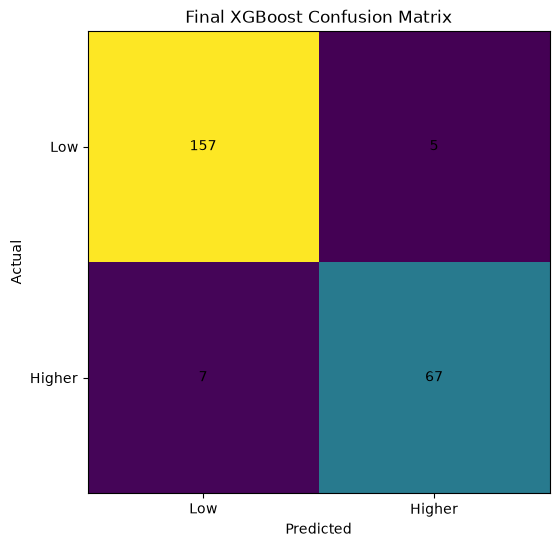

In [39]:
# ============================================================
# CELL 37 — FINAL CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    final_prediction
)

print("=" * 70)
print("FINAL CONFUSION MATRIX")
print("=" * 70)

print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        final_prediction,
        target_names=[
            "Low / Acceptable",
            "Higher Contamination"
        ],
        zero_division=0
    )
)

plt.figure(figsize=(7, 6))

plt.imshow(cm)

plt.title(
    "Final XGBoost Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks(
    [0, 1],
    ["Low", "Higher"]
)

plt.yticks(
    [0, 1],
    ["Low", "Higher"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.show()

TOP 20 FEATURES


,Feature,Importance
0,Dissolved_oxygen_mg_L_Missing,0.119139
1,Latitude,0.116687
2,Dissolved_oxygen_mg_L,0.113589
3,Longitude_physical,0.078256
4,Electric_Conductivity_μS_cm,0.077279
5,Electric_Conductivity_μS_cm_Missing,0.061636
6,Latitude_physical,0.057003
7,Longitude_chemical,0.056316
8,Latitude_chemical,0.048620
9,District_LGD_Code_chemical,0.045791


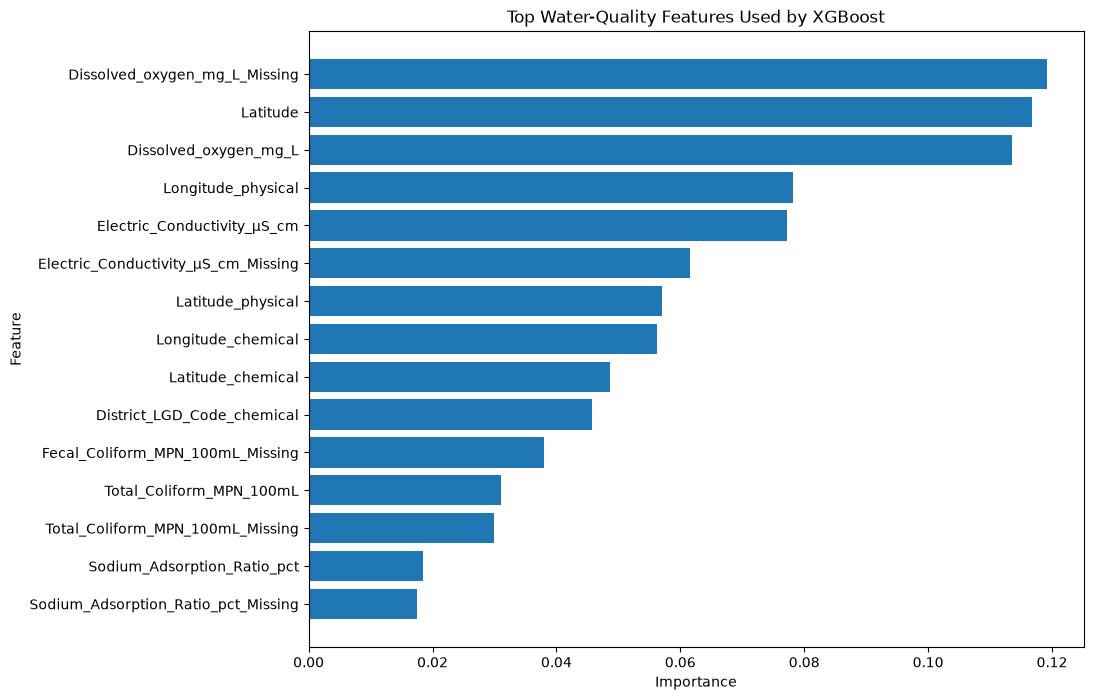

In [40]:
# ============================================================
# CELL 38 — TOP FEATURES
# ============================================================

feature_importance = pd.DataFrame({
    "Feature": X_train_imp.columns,
    "Importance": final_model.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print("=" * 70)
print("TOP 20 FEATURES")
print("=" * 70)

display(
    feature_importance.head(20)
)

plt.figure(figsize=(10, 8))

top_features = feature_importance.head(15)

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title(
    "Top Water-Quality Features Used by XGBoost"
)

plt.show()

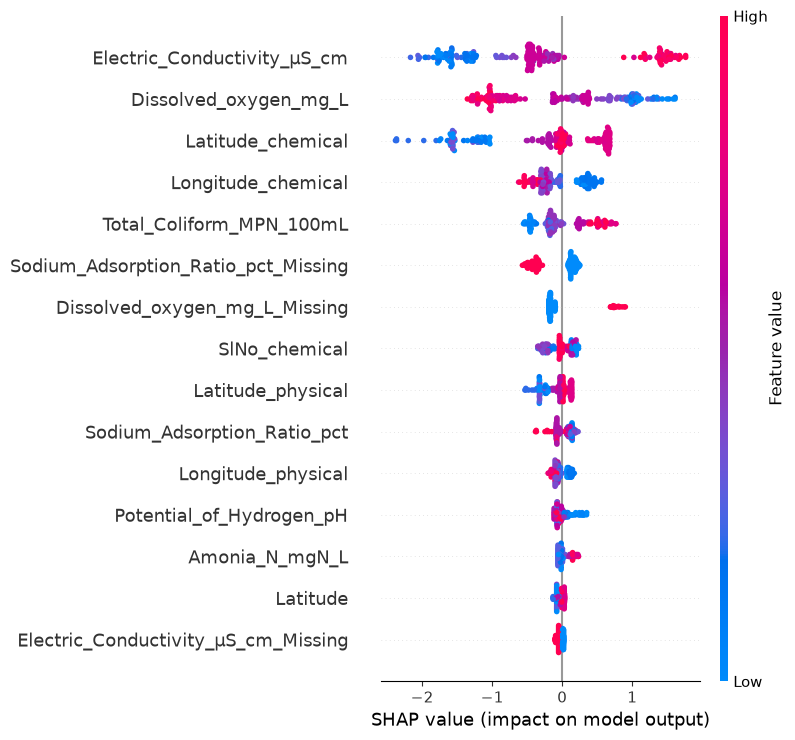

In [41]:
import shap

sample_size = min(200, len(X_test_imp))
X_shap = X_test_imp.sample(sample_size, random_state=42)

explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_shap)

if isinstance(shap_values, list):
    shap_plot_values = shap_values[1]
else:
    shap_plot_values = shap_values

shap.summary_plot(
    shap_plot_values,
    X_shap,
    max_display=15
)

In [42]:
# ============================================================
# CELL 40 — FINAL PROJECT SUMMARY
# ============================================================

accuracy_final = accuracy_score(
    y_test,
    final_prediction
)

precision_final = precision_score(
    y_test,
    final_prediction,
    zero_division=0
)

recall_final = recall_score(
    y_test,
    final_prediction,
    zero_division=0
)

f1_final = f1_score(
    y_test,
    final_prediction,
    zero_division=0
)

auc_final = roc_auc_score(
    y_test,
    final_probability
)

print("=" * 70)
print("WATER CONTAMINATION PREDICTION")
print("FINAL MODEL PERFORMANCE")
print("=" * 70)

print(f"Model             : Tuned XGBoost")
print(f"Features          : {X_train_imp.shape[1]}")
print(f"Training samples  : {len(X_train_imp)}")
print(f"Testing samples   : {len(X_test_imp)}")
print(f"Training stations : {groups_train.nunique()}")
print(f"Testing stations  : {groups_test.nunique()}")

print("\nPERFORMANCE")
print("-" * 70)

print(f"Accuracy          : {accuracy_final:.2%}")
print(f"Precision         : {precision_final:.2%}")
print(f"Recall            : {recall_final:.2%}")
print(f"F1 Score          : {f1_final:.2%}")
print(f"ROC-AUC           : {auc_final:.4f}")

print("\nDECISION THRESHOLD")
print("-" * 70)
print(f"Threshold         : {FINAL_THRESHOLD}")

print("\n✓ FINAL MODEL READY")

WATER CONTAMINATION PREDICTION
FINAL MODEL PERFORMANCE
Model             : Tuned XGBoost
Features          : 34
Training samples  : 809
Testing samples   : 236
Training stations : 121
Testing stations  : 31

PERFORMANCE
----------------------------------------------------------------------
Accuracy          : 94.92%
Precision         : 93.06%
Recall            : 90.54%
F1 Score          : 91.78%
ROC-AUC           : 0.9840

DECISION THRESHOLD
----------------------------------------------------------------------
Threshold         : 0.58

✓ FINAL MODEL READY


In [43]:
# ============================================================
# CELL 41 — FEATURE ABLATION / ROBUSTNESS TEST
# ============================================================

from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from xgboost import XGBClassifier
import pandas as pd
import numpy as np

print("=" * 70)
print("FEATURE ABLATION / ROBUSTNESS TEST")
print("=" * 70)

# ------------------------------------------------------------
# 1. Start from the original feature sets
# ------------------------------------------------------------

X_train_base = X_train.copy()
X_test_base = X_test.copy()

# ------------------------------------------------------------
# 2. Define potentially location / identifier related features
# ------------------------------------------------------------

location_identifier_features = [
    "Latitude",
    "Longitude",
    "Latitude_chemical",
    "Longitude_chemical",
    "Latitude_physical",
    "Longitude_physical",
    "District_LGD_Code_chemical",
    "District_LGD_Code_physical",
    "SlNo",
    "SlNo_chemical",
    "SlNo_physical"
]

# Keep only columns that actually exist
location_identifier_features = [
    col for col in location_identifier_features
    if col in X_train_base.columns
]

# ------------------------------------------------------------
# 3. Missing-value indicator features
# ------------------------------------------------------------

missing_features = [
    col for col in X_train_base.columns
    if col.endswith("_Missing")
]

# ------------------------------------------------------------
# 4. Create three feature sets
# ------------------------------------------------------------

# MODEL A — Current model
X_train_A = X_train_base.copy()
X_test_A = X_test_base.copy()

# MODEL B — Remove location + identifiers
remove_B = location_identifier_features

X_train_B = X_train_base.drop(
    columns=remove_B,
    errors="ignore"
)

X_test_B = X_test_base.drop(
    columns=remove_B,
    errors="ignore"
)

# MODEL C — Remove location + identifiers + missing indicators
remove_C = list(set(
    location_identifier_features + missing_features
))

X_train_C = X_train_base.drop(
    columns=remove_C,
    errors="ignore"
)

X_test_C = X_test_base.drop(
    columns=remove_C,
    errors="ignore"
)

print("\nFEATURE COUNTS")
print("-" * 70)
print(f"Model A - Current features              : {X_train_A.shape[1]}")
print(f"Model B - No location/identifier        : {X_train_B.shape[1]}")
print(f"Model C - No location/ID/missing        : {X_train_C.shape[1]}")

print("\nRemoved location/identifier features:")
print(location_identifier_features)

print(f"\nMissing indicator features removed in Model C: {len(missing_features)}")


# ------------------------------------------------------------
# 5. Function to train and evaluate XGBoost
# ------------------------------------------------------------

def run_ablation_model(Xtr, Xte, model_name):

    # Median imputation
    imputer = SimpleImputer(strategy="median")

    Xtr_imp = pd.DataFrame(
        imputer.fit_transform(Xtr),
        columns=Xtr.columns,
        index=Xtr.index
    )

    Xte_imp = pd.DataFrame(
        imputer.transform(Xte),
        columns=Xte.columns,
        index=Xte.index
    )

    # XGBoost
    model = XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    )

    model.fit(Xtr_imp, y_train)

    # Probability
    probability = model.predict_proba(Xte_imp)[:, 1]

    # Use the same final threshold
    prediction = (probability >= FINAL_THRESHOLD).astype(int)

    accuracy = accuracy_score(y_test, prediction)
    precision = precision_score(y_test, prediction, zero_division=0)
    recall = recall_score(y_test, prediction, zero_division=0)
    f1 = f1_score(y_test, prediction, zero_division=0)
    roc_auc = roc_auc_score(y_test, probability)

    return {
        "Model": model_name,
        "Features": Xtr.shape[1],
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    }


# ------------------------------------------------------------
# 6. Run all three models
# ------------------------------------------------------------

results_A = run_ablation_model(
    X_train_A,
    X_test_A,
    "A - Current Features"
)

results_B = run_ablation_model(
    X_train_B,
    X_test_B,
    "B - No Location/Identifiers"
)

results_C = run_ablation_model(
    X_train_C,
    X_test_C,
    "C - No Location/ID/Missing"
)

# ------------------------------------------------------------
# 7. Display comparison
# ------------------------------------------------------------

ablation_results = pd.DataFrame([
    results_A,
    results_B,
    results_C
])

print("\n")
print("=" * 70)
print("ROBUSTNESS COMPARISON")
print("=" * 70)

display(
    ablation_results.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}",
        "ROC-AUC": "{:.4f}"
    })
)

print("\n" + "=" * 70)
print("INTERPRETATION")
print("=" * 70)

print("""
Model A = Current model
Model B = Removes geographic and identifier variables
Model C = Removes geographic, identifier and missingness variables

If Model B remains strong, the model is not heavily dependent
on geographic/identifier information.

If Model C also remains strong, the model is learning primarily
from actual water-quality measurements.

Note: These models use the same held-out station test set and
the same decision threshold (0.58) for comparison.
""")

FEATURE ABLATION / ROBUSTNESS TEST

FEATURE COUNTS
----------------------------------------------------------------------
Model A - Current features              : 34
Model B - No location/identifier        : 23
Model C - No location/ID/missing        : 14

Removed location/identifier features:
['Latitude', 'Longitude', 'Latitude_chemical', 'Longitude_chemical', 'Latitude_physical', 'Longitude_physical', 'District_LGD_Code_chemical', 'District_LGD_Code_physical', 'SlNo', 'SlNo_chemical', 'SlNo_physical']

Missing indicator features removed in Model C: 9


ROBUSTNESS COMPARISON


,Model,Features,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,A - Current Features,34,94.49%,92.96%,89.19%,91.03%,0.9856
1,B - No Location/Identifiers,23,91.10%,84.42%,87.84%,86.09%,0.9807
2,C - No Location/ID/Missing,14,91.53%,84.62%,89.19%,86.84%,0.9748



INTERPRETATION

Model A = Current model
Model B = Removes geographic and identifier variables
Model C = Removes geographic, identifier and missingness variables

If Model B remains strong, the model is not heavily dependent
on geographic/identifier information.

If Model C also remains strong, the model is learning primarily
from actual water-quality measurements.

Note: These models use the same held-out station test set and
the same decision threshold (0.58) for comparison.



In [44]:
# ============================================================
# CELL 42 — INDEPENDENT VALIDATION
# ============================================================

from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from xgboost import XGBClassifier
import pandas as pd
import numpy as np

print("=" * 70)
print("INDEPENDENT STATION-LEVEL VALIDATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Create a fresh station-level validation split
#    from the existing TRAINING data only
# ------------------------------------------------------------

# Recover station information for training rows
train_station_info = model_data.loc[X_train.index, "Station"]

gss_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=123
)

train_idx, val_idx = next(
    gss_val.split(
        X_train,
        y_train,
        groups=train_station_info
    )
)

X_train_val = X_train.iloc[train_idx].copy()
X_val = X_train.iloc[val_idx].copy()

y_train_val = y_train.iloc[train_idx].copy()
y_val = y_train.iloc[val_idx].copy()

stations_train_val = train_station_info.iloc[train_idx]
stations_val = train_station_info.iloc[val_idx]

print("\nDATA SPLIT")
print("-" * 70)
print(f"Training samples       : {len(X_train_val)}")
print(f"Validation samples     : {len(X_val)}")
print(f"Training stations      : {stations_train_val.nunique()}")
print(f"Validation stations    : {stations_val.nunique()}")

# Check station leakage
overlap = set(stations_train_val.unique()) & set(stations_val.unique())

print(f"Station overlap        : {len(overlap)}")

if len(overlap) == 0:
    print("✓ No station leakage")
else:
    print("⚠ WARNING: Station overlap detected")


# ------------------------------------------------------------
# 2. Imputation
# ------------------------------------------------------------

validation_imputer = SimpleImputer(strategy="median")

X_train_val_imp = pd.DataFrame(
    validation_imputer.fit_transform(X_train_val),
    columns=X_train_val.columns,
    index=X_train_val.index
)

X_val_imp = pd.DataFrame(
    validation_imputer.transform(X_val),
    columns=X_val.columns,
    index=X_val.index
)


# ------------------------------------------------------------
# 3. Train XGBoost
#    Use the same tuned parameters used previously
# ------------------------------------------------------------

validation_model = XGBClassifier(
    n_estimators=tuned_xgb.get_params()["n_estimators"],
    max_depth=tuned_xgb.get_params()["max_depth"],
    learning_rate=tuned_xgb.get_params()["learning_rate"],
    subsample=tuned_xgb.get_params()["subsample"],
    colsample_bytree=tuned_xgb.get_params()["colsample_bytree"],
    min_child_weight=tuned_xgb.get_params()["min_child_weight"],
    gamma=tuned_xgb.get_params()["gamma"],
    reg_alpha=tuned_xgb.get_params()["reg_alpha"],
    reg_lambda=tuned_xgb.get_params()["reg_lambda"],
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

validation_model.fit(
    X_train_val_imp,
    y_train_val
)


# ------------------------------------------------------------
# 4. Find the BEST threshold using VALIDATION DATA
# ------------------------------------------------------------

val_probability = validation_model.predict_proba(
    X_val_imp
)[:, 1]

thresholds = np.arange(0.30, 0.71, 0.01)

threshold_results = []

for threshold in thresholds:

    val_prediction = (
        val_probability >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_val,
            val_prediction
        ),
        "Precision": precision_score(
            y_val,
            val_prediction,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val,
            val_prediction,
            zero_division=0
        ),
        "F1": f1_score(
            y_val,
            val_prediction,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

# Select threshold based on F1
best_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

VALIDATION_THRESHOLD = float(
    best_row["Threshold"]
)

print("\n")
print("=" * 70)
print("VALIDATION THRESHOLD")
print("=" * 70)

print(
    f"Best threshold : {VALIDATION_THRESHOLD:.2f}"
)

print(
    f"Validation accuracy : "
    f"{best_row['Accuracy']:.2%}"
)

print(
    f"Validation precision : "
    f"{best_row['Precision']:.2%}"
)

print(
    f"Validation recall : "
    f"{best_row['Recall']:.2%}"
)

print(
    f"Validation F1 : "
    f"{best_row['F1']:.2%}"
)


# ------------------------------------------------------------
# 5. FINAL EVALUATION ON THE ORIGINAL HELD-OUT TEST SET
# ------------------------------------------------------------
# IMPORTANT:
# The test set has never been used to select the threshold.
# Therefore this is a more independent estimate.

test_probability_validation = validation_model.predict_proba(
    X_test_imp
)[:, 1]

test_prediction_validation = (
    test_probability_validation >= VALIDATION_THRESHOLD
).astype(int)

final_validation_accuracy = accuracy_score(
    y_test,
    test_prediction_validation
)

final_validation_precision = precision_score(
    y_test,
    test_prediction_validation,
    zero_division=0
)

final_validation_recall = recall_score(
    y_test,
    test_prediction_validation,
    zero_division=0
)

final_validation_f1 = f1_score(
    y_test,
    test_prediction_validation,
    zero_division=0
)

final_validation_auc = roc_auc_score(
    y_test,
    test_probability_validation
)


# ------------------------------------------------------------
# 6. Display independent test performance
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("INDEPENDENT TEST PERFORMANCE")
print("=" * 70)

print(
    f"Accuracy       : "
    f"{final_validation_accuracy:.2%}"
)

print(
    f"Precision      : "
    f"{final_validation_precision:.2%}"
)

print(
    f"Recall         : "
    f"{final_validation_recall:.2%}"
)

print(
    f"F1 Score       : "
    f"{final_validation_f1:.2%}"
)

print(
    f"ROC-AUC        : "
    f"{final_validation_auc:.4f}"
)

print(
    f"Threshold      : "
    f"{VALIDATION_THRESHOLD:.2f}"
)


# ------------------------------------------------------------
# 7. Compare with previous threshold-optimized result
# ------------------------------------------------------------

comparison = pd.DataFrame({
    "Evaluation": [
        "Previous Test Result",
        "Independent Test Result"
    ],
    "Accuracy": [
        accuracy_score(y_test, final_prediction),
        final_validation_accuracy
    ],
    "Precision": [
        precision_score(
            y_test,
            final_prediction,
            zero_division=0
        ),
        final_validation_precision
    ],
    "Recall": [
        recall_score(
            y_test,
            final_prediction,
            zero_division=0
        ),
        final_validation_recall
    ],
    "F1 Score": [
        f1_score(
            y_test,
            final_prediction,
            zero_division=0
        ),
        final_validation_f1
    ],
    "ROC-AUC": [
        roc_auc_score(
            y_test,
            final_probability
        ),
        final_validation_auc
    ]
})

print("\n")
print("=" * 70)
print("PREVIOUS vs INDEPENDENT TEST")
print("=" * 70)

display(
    comparison.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}",
        "ROC-AUC": "{:.4f}"
    })
)

print("\n✓ Independent validation completed.")

INDEPENDENT STATION-LEVEL VALIDATION

DATA SPLIT
----------------------------------------------------------------------
Training samples       : 642
Validation samples     : 167
Training stations      : 96
Validation stations    : 25
Station overlap        : 0
✓ No station leakage


VALIDATION THRESHOLD
Best threshold : 0.41
Validation accuracy : 92.81%
Validation precision : 90.91%
Validation recall : 93.33%
Validation F1 : 92.11%


INDEPENDENT TEST PERFORMANCE
Accuracy       : 93.22%
Precision      : 86.25%
Recall         : 93.24%
F1 Score       : 89.61%
ROC-AUC        : 0.9837
Threshold      : 0.41


PREVIOUS vs INDEPENDENT TEST


,Evaluation,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Previous Test Result,94.92%,93.06%,90.54%,91.78%,0.9840
1,Independent Test Result,93.22%,86.25%,93.24%,89.61%,0.9837



✓ Independent validation completed.


In [45]:
# ============================================================
# CELL 43 — FINAL WATER CONTAMINATION PREDICTION SYSTEM
# ============================================================

import numpy as np
import pandas as pd

# Use the independently validated model and threshold
DEPLOYED_MODEL = validation_model
DEPLOYED_IMPUTER = validation_imputer
DEPLOYED_THRESHOLD = VALIDATION_THRESHOLD

# ------------------------------------------------------------
# Prediction function
# ------------------------------------------------------------

def predict_water_contamination(input_data):

    # Convert input to DataFrame
    input_df = pd.DataFrame([input_data])

    # Make sure all model features are present
    missing_columns = [
        col for col in X_train.columns
        if col not in input_df.columns
    ]

    for col in missing_columns:
        input_df[col] = np.nan

    # Keep exactly the training feature order
    input_df = input_df[X_train.columns]

    # Impute missing values
    input_imp = pd.DataFrame(
        DEPLOYED_IMPUTER.transform(input_df),
        columns=input_df.columns
    )

    # Predict probability
    probability = DEPLOYED_MODEL.predict_proba(
        input_imp
    )[0, 1]

    # Apply validated threshold
    prediction = int(
        probability >= DEPLOYED_THRESHOLD
    )

    # Risk level
    if probability < 0.30:
        risk = "LOW"
    elif probability < 0.60:
        risk = "MEDIUM"
    else:
        risk = "HIGH"

    # Final label
    if prediction == 1:
        result = "CONTAMINATED"
    else:
        result = "NOT CONTAMINATED"

    return {
        "Prediction": result,
        "Contamination Probability": probability,
        "Risk Level": risk,
        "Decision Threshold": DEPLOYED_THRESHOLD
    }


print("=" * 70)
print("FINAL WATER CONTAMINATION PREDICTION SYSTEM")
print("=" * 70)

print(f"Model              : Validated XGBoost")
print(f"Features           : {X_train.shape[1]}")
print(f"Decision Threshold : {DEPLOYED_THRESHOLD:.2f}")
print()
print("✓ Prediction function created successfully")

FINAL WATER CONTAMINATION PREDICTION SYSTEM
Model              : Validated XGBoost
Features           : 34
Decision Threshold : 0.41

✓ Prediction function created successfully


In [46]:
# ============================================================
# CELL 44 — TEST FINAL PREDICTION
# ============================================================

# Use the median values from the training data
# to create a safe example input.

example_input = X_train.median(numeric_only=True).to_dict()

result = predict_water_contamination(example_input)

print("=" * 70)
print("WATER CONTAMINATION PREDICTION")
print("=" * 70)

print(f"Prediction             : {result['Prediction']}")
print(
    f"Contamination Probability : "
    f"{result['Contamination Probability']:.2%}"
)
print(f"Risk Level             : {result['Risk Level']}")
print(
    f"Decision Threshold     : "
    f"{result['Decision Threshold']:.2f}"
)

print("=" * 70)

WATER CONTAMINATION PREDICTION
Prediction             : CONTAMINATED
Contamination Probability : 75.19%
Risk Level             : HIGH
Decision Threshold     : 0.41


In [ ]:
# ============================================================
# CELL 45 — INTERACTIVE WATER QUALITY PREDICTION
# ============================================================

from IPython.display import display
import ipywidgets as widgets

print("=" * 70)
print("WATER CONTAMINATION PREDICTION")
print("=" * 70)

# ------------------------------------------------------------
# Identify useful water-quality features
# ------------------------------------------------------------

preferred_features = [
    "Dissolved_oxygen_mg_L",
    "Electric_Conductivity_μS_cm",
    "Potential_of_Hydrogen_pH",
    "Total_Coliform_MPN_100mL",
    "Fecal_Coliform_MPN_100mL",
    "Sodium_Adsorption_Ratio_pct",
    "Amonia_N_mgN_L",
    "Chemical_Oxygen_Demand_mg_L"
]

available_features = [
    f for f in preferred_features
    if f in X_train.columns
]

print("\nAvailable water-quality inputs:")
for f in available_features:
    print("•", f)

print("\nEnter values below. Other model features will be")
print("automatically filled using training-data medians.")
print("-" * 70)


# ------------------------------------------------------------
# Create input widgets
# ------------------------------------------------------------

widgets_dict = {}

for feature in available_features:

    median_value = X_train[feature].median()

    widgets_dict[feature] = widgets.FloatText(
        value=float(median_value)
        if pd.notna(median_value)
        else 0.0,
        description=feature[:18],
        style={"description_width": "initial"},
        layout=widgets.Layout(width="500px")
    )

    display(widgets_dict[feature])


# ------------------------------------------------------------
# Prediction button
# ------------------------------------------------------------

predict_button = widgets.Button(
    description="Predict Water Contamination",
    button_style="primary",
    layout=widgets.Layout(width="300px")
)

output = widgets.Output()


def make_prediction(button):

    with output:

        output.clear_output()

        # Create input dictionary
        user_input = {}

        for feature in X_train.columns:

            if feature in widgets_dict:
                user_input[feature] = widgets_dict[feature].value
            else:
                # Use training median for unspecified features
                median_value = X_train[feature].median()

                user_input[feature] = (
                    float(median_value)
                    if pd.notna(median_value)
                    else 0.0
                )

        # Prediction
        result = predict_water_contamination(
            user_input
        )

        probability = result[
            "Contamination Probability"
        ]

        print("\n")
        print("=" * 70)
        print("PREDICTION RESULT")
        print("=" * 70)

        print(
            f"Prediction              : "
            f"{result['Prediction']}"
        )

        print(
            f"Contamination Probability: "
            f"{probability:.2%}"
        )

        print(
            f"Risk Level              : "
            f"{result['Risk Level']}"
        )

        print(
            f"Decision Threshold      : "
            f"{result['Decision Threshold']:.2f}"
        )

        print("=" * 70)

        # Simple recommendation
        if result["Prediction"] == "CONTAMINATED":

            print("\n⚠ WARNING")
            print(
                "The water sample is predicted to have "
                "a contamination risk."
            )
            print(
                "Further laboratory testing and appropriate "
                "water-quality assessment are recommended."
            )

        else:

            print("\n✓ RESULT")
            print(
                "The water sample is predicted as "
                "not contaminated by the model."
            )
            print(
                "Routine water-quality monitoring is recommended."
            )

        print("=" * 70)


predict_button.on_click(make_prediction)

display(predict_button)
display(output)

WATER CONTAMINATION PREDICTION

Available water-quality inputs:
• Dissolved_oxygen_mg_L
• Electric_Conductivity_μS_cm
• Potential_of_Hydrogen_pH
• Total_Coliform_MPN_100mL
• Fecal_Coliform_MPN_100mL
• Sodium_Adsorption_Ratio_pct
• Amonia_N_mgN_L

Enter values below. Other model features will be
automatically filled using training-data medians.
----------------------------------------------------------------------


FloatText(value=5.3, description='Dissolved_oxygen_m', layout=Layout(width='500px'), style=DescriptionStyle(de…

FloatText(value=1077.5, description='Electric_Conductiv', layout=Layout(width='500px'), style=DescriptionStyle…

FloatText(value=7.61, description='Potential_of_Hydro', layout=Layout(width='500px'), style=DescriptionStyle(d…

FloatText(value=298.0, description='Total_Coliform_MPN', layout=Layout(width='500px'), style=DescriptionStyle(…

FloatText(value=7.0, description='Fecal_Coliform_MPN', layout=Layout(width='500px'), style=DescriptionStyle(de…

FloatText(value=2.7, description='Sodium_Adsorption_', layout=Layout(width='500px'), style=DescriptionStyle(de…

FloatText(value=0.6, description='Amonia_N_mgN_L', layout=Layout(width='500px'), style=DescriptionStyle(descri…

Button(button_style='primary', description='Predict Water Contamination', layout=Layout(width='300px'), style=…

Output()

In [48]:
# ============================================================
# CELL 46 — TRAINING vs TESTING ACCURACY
# ============================================================

from sklearn.metrics import accuracy_score

# ------------------------------------------------------------
# 1. Training predictions
# ------------------------------------------------------------

train_probability = validation_model.predict_proba(
    X_train_val_imp
)[:, 1]

train_prediction = (
    train_probability >= VALIDATION_THRESHOLD
).astype(int)

training_accuracy = accuracy_score(
    y_train_val,
    train_prediction
)

# ------------------------------------------------------------
# 2. Independent testing predictions
# ------------------------------------------------------------

test_probability = validation_model.predict_proba(
    X_test_imp
)[:, 1]

test_prediction = (
    test_probability >= VALIDATION_THRESHOLD
).astype(int)

testing_accuracy = accuracy_score(
    y_test,
    test_prediction
)

# ------------------------------------------------------------
# 3. Display results
# ------------------------------------------------------------

print("=" * 70)
print("TRAINING vs TESTING ACCURACY")
print("=" * 70)

print(f"Training Accuracy : {training_accuracy:.2%}")
print(f"Testing Accuracy  : {testing_accuracy:.2%}")

print("-" * 70)

difference = training_accuracy - testing_accuracy

print(f"Accuracy Difference: {difference:.2%}")

print("=" * 70)

if difference < 0.05:
    print("✓ Good generalization")
elif difference < 0.10:
    print("⚠ Moderate difference — monitor for overfitting")
else:
    print("⚠ Large difference — possible overfitting")

TRAINING vs TESTING ACCURACY
Training Accuracy : 95.33%
Testing Accuracy  : 93.22%
----------------------------------------------------------------------
Accuracy Difference: 2.11%
✓ Good generalization


COMPARISON OF ALL MODELS


,Model,Evaluation,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Tuned XGBoost,Held-out test,94.49%,91.78%,90.54%,91.16%,0.9840
1,Validated XGBoost,Independent test,93.22%,86.25%,93.24%,89.61%,0.9837
2,Original XGBoost,Held-out test,94.07%,91.67%,89.19%,90.41%,0.9835
3,CatBoost,Held-out test,92.37%,88.89%,86.49%,87.67%,0.9822
4,Random Forest,Held-out test,91.10%,84.42%,87.84%,86.09%,0.9774
5,Extra Trees,Held-out test,89.83%,82.89%,85.14%,84.00%,0.9518


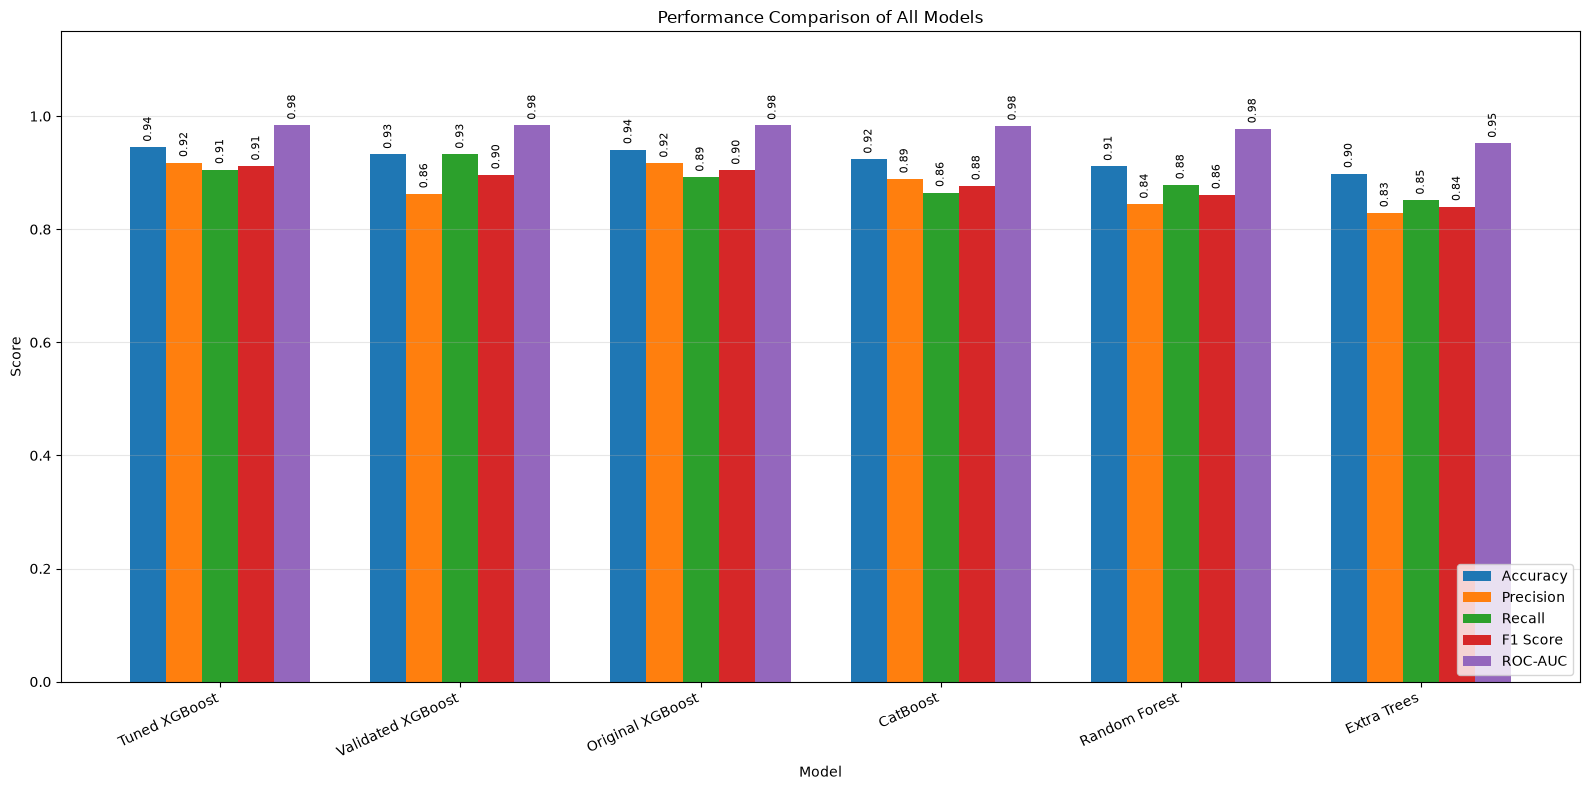


Best ROC-AUC model: Tuned XGBoost
Best ROC-AUC: 0.9840


In [51]:
# ============================================================
# MODEL COMPARISON — ALL MODELS WITH BAR GRAPH
# ============================================================

model_comparison = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Evaluation": "Held-out test",
        "Accuracy": rf_accuracy,
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1 Score": rf_f1,
        "ROC-AUC": rf_auc
    },
    {
        "Model": "Extra Trees",
        "Evaluation": "Held-out test",
        "Accuracy": accuracy_score(y_test, extra_pred),
        "Precision": precision_score(y_test, extra_pred, zero_division=0),
        "Recall": recall_score(y_test, extra_pred, zero_division=0),
        "F1 Score": f1_score(y_test, extra_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, extra_prob)
    },
    {
        "Model": "Original XGBoost",
        "Evaluation": "Held-out test",
        "Accuracy": accuracy_score(y_test, xgb_pred),
        "Precision": precision_score(y_test, xgb_pred, zero_division=0),
        "Recall": recall_score(y_test, xgb_pred, zero_division=0),
        "F1 Score": f1_score(y_test, xgb_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, xgb_prob)
    },
    {
        "Model": "CatBoost",
        "Evaluation": "Held-out test",
        "Accuracy": accuracy_score(y_test, cat_pred),
        "Precision": precision_score(y_test, cat_pred, zero_division=0),
        "Recall": recall_score(y_test, cat_pred, zero_division=0),
        "F1 Score": f1_score(y_test, cat_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, cat_prob)
    },
    {
        "Model": "Tuned XGBoost",
        "Evaluation": "Held-out test",
        "Accuracy": tuned_accuracy,
        "Precision": tuned_precision,
        "Recall": tuned_recall,
        "F1 Score": tuned_f1,
        "ROC-AUC": tuned_auc
    },
    {
        "Model": "Validated XGBoost",
        "Evaluation": "Independent test",
        "Accuracy": final_validation_accuracy,
        "Precision": final_validation_precision,
        "Recall": final_validation_recall,
        "F1 Score": final_validation_f1,
        "ROC-AUC": final_validation_auc
    }
])

model_comparison = model_comparison.sort_values(
    "ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("=" * 90)
print("COMPARISON OF ALL MODELS")
print("=" * 90)

display(
    model_comparison.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}",
        "ROC-AUC": "{:.4f}"
    })
)

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

x_positions = np.arange(len(model_comparison))
bar_width = 0.15

plt.figure(figsize=(16, 8))

for index, metric in enumerate(metrics):
    values = model_comparison[metric].to_numpy()
    offset = (index - (len(metrics) - 1) / 2) * bar_width
    bars = plt.bar(
        x_positions + offset,
        values,
        width=bar_width,
        label=metric
    )

    for bar, value in zip(bars, values):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.01,
            f"{value:.2f}",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=90
        )

plt.xticks(
    x_positions,
    model_comparison["Model"],
    rotation=25,
    ha="right"
)
plt.ylim(0, 1.15)
plt.ylabel("Score")
plt.xlabel("Model")
plt.title("Performance Comparison of All Models")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

best_result = model_comparison.iloc[0]
print("\nBest ROC-AUC model:", best_result["Model"])
print("Best ROC-AUC:", f"{best_result['ROC-AUC']:.4f}")